# Home Assignment 3 — CS5720 Neural Networks and Deep Learning
**Student:** Palash Palit

## How to run this notebook
1. **Runtime → Change runtime type → T4 GPU → Save.**
2. **Runtime → Run all.** It takes about 5–10 minutes on a T4 GPU.
3. Scroll to the **last cell** and copy its whole output. It has every number needed for the assignment document.

Q1 implements convolution with NumPy only. Q2 compares a frozen pretrained ResNet50 (feature extraction) with a partly fine-tuned one.

## Q1: Convolution from Scratch (NumPy only, no built-in convolution)

In [9]:
import numpy as np

# a. Store the input and filter as NumPy arrays
input_matrix = np.array([
    [1, 1, 1, 0, 0],
    [0, 1, 1, 1, 0],
    [0, 0, 1, 1, 1],
    [0, 0, 1, 1, 0],
    [0, 1, 1, 0, 0],
])

kernel = np.array([
    [1, 0, 1],
    [0, 1, 0],
    [1, 0, 1],
])


def convolve2d(image, kernel, stride=1, padding=0):
    """Slide `kernel` over `image` and return the feature map.

    At each valid location, take the patch under the kernel, multiply it
    element by element with the kernel, and sum the products (a dot product).
    """
    # Add a border of zeros if padding > 0
    if padding > 0:
        image = np.pad(image, padding, mode="constant", constant_values=0)

    n = image.shape[0]      # input size N (after padding)
    f = kernel.shape[0]     # filter size F

    # Output size: floor((N - F) / S) + 1  (padding is already applied to N)
    out_size = (n - f) // stride + 1
    output = np.zeros((out_size, out_size), dtype=int)

    # b. Slide the filter over the input matrix
    for i in range(out_size):
        for j in range(out_size):
            row, col = i * stride, j * stride
            patch = image[row:row + f, col:col + f]
            # c. Dot product of the patch and the kernel at this location
            output[i, j] = np.sum(patch * kernel)
    return output


feature_map = convolve2d(input_matrix, kernel, stride=1, padding=0)

print("Input (5x5):")
print(input_matrix)
print("\nFilter (3x3):")
print(kernel)

# d. Print the complete output feature map
print("\nOutput feature map (stride = 1, padding = 0):")
print(feature_map)

# e. Print the output shape
print("\nOutput shape:", feature_map.shape)

# Show the work for the top-left position
patch = input_matrix[0:3, 0:3]
print("\nExample - top-left position (0,0):")
print("patch * kernel =")
print(patch * kernel)
print("sum =", np.sum(patch * kernel))

# f. Effect of changing the stride from 1 to 2
feature_map_s2 = convolve2d(input_matrix, kernel, stride=2, padding=0)
print("\nOutput feature map with stride = 2 (for comparison):")
print(feature_map_s2)
print("Output shape:", feature_map_s2.shape)

print("""
Effect of stride 2:
With stride 1 the filter moves one cell at a time and visits every valid
position, giving a (5 - 3)/1 + 1 = 3 x 3 output. With stride 2 the filter
jumps two cells each step, so it only visits positions (0,0), (0,2), (2,0)
and (2,2). The output shrinks to (5 - 3)/2 + 1 = 2 x 2, and its values are
the four corner values of the stride-1 output. A larger stride reduces the
output size and computation but skips positions, so some detail is lost.
""")

Input (5x5):
[[1 1 1 0 0]
 [0 1 1 1 0]
 [0 0 1 1 1]
 [0 0 1 1 0]
 [0 1 1 0 0]]

Filter (3x3):
[[1 0 1]
 [0 1 0]
 [1 0 1]]

Output feature map (stride = 1, padding = 0):
[[4 3 4]
 [2 4 3]
 [2 3 4]]

Output shape: (3, 3)

Example - top-left position (0,0):
patch * kernel =
[[1 0 1]
 [0 1 0]
 [0 0 1]]
sum = 4

Output feature map with stride = 2 (for comparison):
[[4 4]
 [2 4]]
Output shape: (2, 2)

Effect of stride 2:
With stride 1 the filter moves one cell at a time and visits every valid
position, giving a (5 - 3)/1 + 1 = 3 x 3 output. With stride 2 the filter
jumps two cells each step, so it only visits positions (0,0), (0,2), (2,0)
and (2,2). The output shrinks to (5 - 3)/2 + 1 = 2 x 2, and its values are
the four corner values of the stride-1 output. A larger stride reduces the
output size and computation but skips positions, so some detail is lost.



## Q2: Transfer Learning — Freeze vs. Fine-Tune
- **Model:** ResNet50 pretrained on ImageNet (from `tf.keras.applications`)
- **Dataset:** TensorFlow flowers — 3,670 photos, 5 classes (daisy, dandelion, roses, sunflowers, tulips); 80% training, 20% validation
- **Experiment A (feature extraction):** freeze the whole ResNet50 base, replace the classifier, train only the new classifier
- **Experiment B (fine-tuning):** start again from the pretrained ResNet50, unfreeze the last convolutional block (`conv5`), train it together with the new classifier
- Both experiments train for the **same number of epochs**.

In [10]:
# Setup: imports, GPU check, and settings shared by both experiments
import os, time, tarfile
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

print("TensorFlow version:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))

tf.keras.utils.set_random_seed(42)   # makes the runs repeatable
IMG_SIZE = (224, 224)                 # ResNet50's standard input size
BATCH_SIZE = 32
EPOCHS = 5                            # same number of epochs for both experiments
WEIGHTS = "imagenet"                  # pretrained ImageNet weights

TensorFlow version: 2.21.0
GPU available: True


In [11]:
# Load the flowers dataset (downloads automatically, about 220 MB)
DATA_URL = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
archive = tf.keras.utils.get_file("flower_photos.tgz", origin=DATA_URL)
data_root = os.path.join(os.path.dirname(archive), "flowers_extracted")
if not os.path.exists(os.path.join(data_root, "flower_photos")):
    with tarfile.open(archive) as tar:
        try:
            tar.extractall(data_root, filter="data")   # safe extraction (Python 3.12+)
        except TypeError:
            tar.extractall(data_root)                  # older Python versions
DATA_DIR = os.path.join(data_root, "flower_photos")

# 80% training / 20% validation split; each subfolder is one class
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR, validation_split=0.2, subset="training", seed=123,
    image_size=IMG_SIZE, batch_size=BATCH_SIZE)
val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR, validation_split=0.2, subset="validation", seed=123,
    image_size=IMG_SIZE, batch_size=BATCH_SIZE)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
print("Classes:", class_names)

# ResNet50 expects its own preprocessing (channel order and mean subtraction)
def prep(images, labels):
    return preprocess_input(images), labels

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.map(prep, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
val_ds = val_ds.map(prep, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

Found 3670 files belonging to 5 classes.
Using 2936 files for training.
Found 3670 files belonging to 5 classes.
Using 734 files for validation.
Classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


In [12]:
def build_model(fine_tune):
    """Pretrained ResNet50 base + a new classifier for our classes.

    fine_tune=False -> Experiment A: the whole base is frozen.
    fine_tune=True  -> Experiment B: the last conv block (conv5_*) is unfrozen.
    """
    base = ResNet50(include_top=False,            # drop the original 1000-class ImageNet classifier
                    weights=WEIGHTS,
                    input_shape=IMG_SIZE + (3,),
                    pooling="avg")                # global average pooling -> 2048 features

    if not fine_tune:
        base.trainable = False                    # freeze every layer in the base
    else:
        base.trainable = True
        for layer in base.layers:
            # Unfreeze only the last convolutional block (conv5). BatchNorm layers stay
            # frozen so their pretrained statistics are not disturbed by our small dataset.
            layer.trainable = (layer.name.startswith("conv5_")
                               and not isinstance(layer, layers.BatchNormalization))

    inputs = layers.Input(shape=IMG_SIZE + (3,))
    x = base(inputs, training=False)              # keep BatchNorm in inference mode
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)   # new classification layer
    return models.Model(inputs, outputs)


def count_params(model):
    trainable = int(sum(np.prod(w.shape) for w in model.trainable_weights))
    frozen = int(sum(np.prod(w.shape) for w in model.non_trainable_weights))
    return trainable, frozen


def run_experiment(name, fine_tune, learning_rate):
    model = build_model(fine_tune)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    trainable, frozen = count_params(model)
    print(f"\n=== {name} ===")
    print(f"Trainable parameters: {trainable:,}   Frozen parameters: {frozen:,}")

    start = time.time()
    history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, verbose=2)
    train_time = time.time() - start

    val_loss, val_acc = model.evaluate(val_ds, verbose=0)
    print(f"Training time: {train_time:.1f} s   Validation accuracy: {val_acc:.4f}")
    return {"name": name, "trainable": trainable, "frozen": frozen,
            "time": train_time, "val_acc": val_acc, "val_loss": val_loss,
            "history": history.history}

### Experiment A — Frozen Feature Extractor

In [13]:
# Only the new Dense layer trains, so a normal learning rate (1e-3) is used.
result_a = run_experiment("Frozen Feature Extractor", fine_tune=False, learning_rate=1e-3)


=== Frozen Feature Extractor ===
Trainable parameters: 10,245   Frozen parameters: 23,587,712
Epoch 1/5
92/92 - 37s - 402ms/step - accuracy: 0.7428 - loss: 0.7114 - val_accuracy: 0.8842 - val_loss: 0.3404
Epoch 2/5
92/92 - 12s - 135ms/step - accuracy: 0.8873 - loss: 0.3206 - val_accuracy: 0.9046 - val_loss: 0.2772
Epoch 3/5
92/92 - 12s - 135ms/step - accuracy: 0.9183 - loss: 0.2372 - val_accuracy: 0.9074 - val_loss: 0.2492
Epoch 4/5
92/92 - 12s - 136ms/step - accuracy: 0.9332 - loss: 0.1992 - val_accuracy: 0.9169 - val_loss: 0.2331
Epoch 5/5
92/92 - 20s - 218ms/step - accuracy: 0.9418 - loss: 0.1697 - val_accuracy: 0.9169 - val_loss: 0.2340
Training time: 94.4 s   Validation accuracy: 0.9169


### Experiment B — Fine-Tuned Network (last conv block unfrozen)

In [14]:
# Pretrained conv5 weights are updated too, so a smaller learning rate (1e-4) is used
# to adjust them gently instead of destroying what they already learned.
result_b = run_experiment("Fine-Tuned Network", fine_tune=True, learning_rate=1e-4)


=== Fine-Tuned Network ===
Trainable parameters: 14,963,717   Frozen parameters: 8,634,240
Epoch 1/5
92/92 - 44s - 476ms/step - accuracy: 0.8389 - loss: 0.4682 - val_accuracy: 0.9060 - val_loss: 0.2456
Epoch 2/5
92/92 - 15s - 165ms/step - accuracy: 0.9370 - loss: 0.1658 - val_accuracy: 0.9237 - val_loss: 0.2213
Epoch 3/5
92/92 - 16s - 173ms/step - accuracy: 0.9779 - loss: 0.0695 - val_accuracy: 0.9278 - val_loss: 0.2066
Epoch 4/5
92/92 - 15s - 160ms/step - accuracy: 0.9891 - loss: 0.0415 - val_accuracy: 0.9183 - val_loss: 0.3665
Epoch 5/5
92/92 - 15s - 160ms/step - accuracy: 0.9891 - loss: 0.0414 - val_accuracy: 0.9346 - val_loss: 0.2660
Training time: 110.1 s   Validation accuracy: 0.9346


### Training Loss Plot and Comparison Table

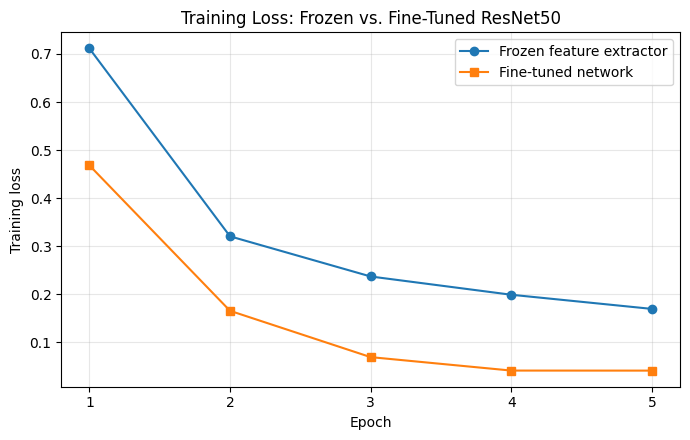

                  Method Trainable Parameters Training Time (s) Validation Accuracy
Frozen Feature Extractor               10,245              94.4              0.9169
      Fine-Tuned Network           14,963,717             110.1              0.9346


In [15]:
epochs_range = range(1, EPOCHS + 1)
plt.figure(figsize=(7, 4.5))
plt.plot(epochs_range, result_a["history"]["loss"], marker="o", label="Frozen feature extractor")
plt.plot(epochs_range, result_b["history"]["loss"], marker="s", label="Fine-tuned network")
plt.xlabel("Epoch"); plt.ylabel("Training loss")
plt.title("Training Loss: Frozen vs. Fine-Tuned ResNet50")
plt.xticks(list(epochs_range)); plt.grid(alpha=0.3); plt.legend()
plt.tight_layout()
plt.savefig("training_loss_comparison.png", dpi=150)
plt.show()

table = pd.DataFrame({
    "Method": [result_a["name"], result_b["name"]],
    "Trainable Parameters": [f"{result_a['trainable']:,}", f"{result_b['trainable']:,}"],
    "Training Time (s)": [f"{result_a['time']:.1f}", f"{result_b['time']:.1f}"],
    "Validation Accuracy": [f"{result_a['val_acc']:.4f}", f"{result_b['val_acc']:.4f}"],
})
print(table.to_string(index=False))

## Results Summary
**Copy the entire output of the cell below and paste it back to Claude** so the assignment document can be completed with your real results.

In [16]:
print("=" * 70)
print("HOME ASSIGNMENT 3 - RESULTS SUMMARY (Palash Palit)")
print("=" * 70)
print("TensorFlow", tf.__version__, "| GPU:", bool(tf.config.list_physical_devices("GPU")))
print("Classes:", class_names, "| epochs per experiment:", EPOCHS)
for r in (result_a, result_b):
    h = r["history"]
    print(f"\n--- {r['name']} ---")
    print(f"Trainable params: {r['trainable']:,} | Frozen params: {r['frozen']:,}")
    print(f"Training time: {r['time']:.1f} s | Final val accuracy: {r['val_acc']:.4f} | val loss: {r['val_loss']:.4f}")
    for i in range(len(h["loss"])):
        print(f"Epoch {i+1}: loss {h['loss'][i]:.4f}  acc {h['accuracy'][i]:.4f}  "
              f"val_loss {h['val_loss'][i]:.4f}  val_acc {h['val_accuracy'][i]:.4f}")
print("=" * 70)

HOME ASSIGNMENT 3 - RESULTS SUMMARY (Palash Palit)
TensorFlow 2.21.0 | GPU: True
Classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips'] | epochs per experiment: 5

--- Frozen Feature Extractor ---
Trainable params: 10,245 | Frozen params: 23,587,712
Training time: 94.4 s | Final val accuracy: 0.9169 | val loss: 0.2340
Epoch 1: loss 0.7114  acc 0.7428  val_loss 0.3404  val_acc 0.8842
Epoch 2: loss 0.3206  acc 0.8873  val_loss 0.2772  val_acc 0.9046
Epoch 3: loss 0.2372  acc 0.9183  val_loss 0.2492  val_acc 0.9074
Epoch 4: loss 0.1992  acc 0.9332  val_loss 0.2331  val_acc 0.9169
Epoch 5: loss 0.1697  acc 0.9418  val_loss 0.2340  val_acc 0.9169

--- Fine-Tuned Network ---
Trainable params: 14,963,717 | Frozen params: 8,634,240
Training time: 110.1 s | Final val accuracy: 0.9346 | val loss: 0.2660
Epoch 1: loss 0.4682  acc 0.8389  val_loss 0.2456  val_acc 0.9060
Epoch 2: loss 0.1658  acc 0.9370  val_loss 0.2213  val_acc 0.9237
Epoch 3: loss 0.0695  acc 0.9779  val_loss 0.2066  va